Cell 0 — Imports

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import json
from datetime import datetime


Cell 1 — Step 1 helpers (global state)

In [2]:
def simulate_global_state(T=20000, D=256, seed=123, mu=-1.5, sigma=0.3, sigma_drift=0.001):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)
    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta  + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))
    return X


Cell 2 — Step 2 helpers (nodes + signals)

In [3]:
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


Cell 3 — Step 5 destruction helper (bit-flip)

In [4]:
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()
    Xd[flips] = 1 - Xd[flips]
    return Xd


Cell 4 — Step 4 dataset used for evaluation (masked windows)

In [5]:
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


Cell 5 — Model class (must match training)

In [6]:
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)


Cell 6 — Load model weights

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

K = 40
window = 128
mask_ratio = 0.15

model = MaskedTimeTransformer(K=K, window=window).to(device)
model.load_state_dict(torch.load("run1_clean_model.pt", map_location=device))
model.eval()

print("loaded on", device)


loaded on cpu


C:\Users\user\AppData\Local\Temp\ipykernel_23596\2184215657.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("run1_clean_model.pt", map_l

Cell 7 — Step 7 info-theory utilities + collectors + baseline

In [8]:
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)

@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = model(xb).cpu().numpy().astype(np.float32)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)

def baseline_predict_window_node_mean(x_masked_np):
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)


Cell 8 — Build base data once (for Step 7 sweeps)

In [9]:
T = 20000
seed_world = 123
seed_nodes = 123

X = simulate_global_state(T=T, seed=seed_world)
subsets = construct_nodes(K=K, seed=seed_nodes)
Z = compute_node_signals(X, subsets)
split = int(0.8 * Z.shape[0])

bins = np.linspace(0, 1, 21)


Cell 9 — Step 7 delta sweep (you edit deltas here)

In [10]:
deltas = np.arange(0.0, 0.55, 0.05)  # edit range however you want

results = []
for delta in deltas:
    Xd = destroy_bitflip_X(X, delta, seed=999)
    Zd = compute_node_signals(Xd, subsets)

    Z_val_d = Zd[split - window:]
    val_ds = MaskedWindowDataset(Z_val_d, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true if H_true > 1e-12 else 0.0

    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true if H_true > 1e-12 else 0.0

    results.append({
        "delta": float(delta),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    })

results[:2], results[-1]


([{'delta': 0.0,
   'H_true': 2.9844851292032937,
   'MI_transformer': 0.056133810959317465,
   'R_transformer': 0.018808541014343184,
   'MI_baseline_window': 0.01603408155057373,
   'R_baseline_window': 0.005372478285678045},
  {'delta': 0.05,
   'H_true': 2.985090087964197,
   'MI_transformer': 0.053207145638926256,
   'R_transformer': 0.01782430146864111,
   'MI_baseline_window': 0.011512989215473723,
   'R_baseline_window': 0.0038568314108488005}],
 {'delta': 0.5,
  'H_true': 2.979319222769551,
  'MI_transformer': 0.028895808245564147,
  'R_transformer': 0.009698795625768104,
  'MI_baseline_window': 1.5896254557556944e-05,
  'R_baseline_window': 5.335532505570153e-06})

Cell 10 — Plot + save (end of notebook)

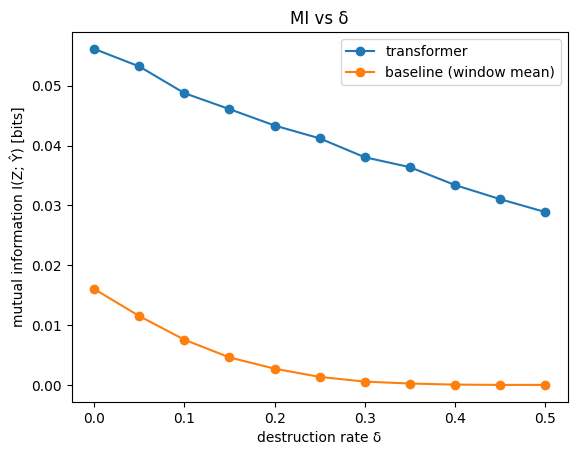

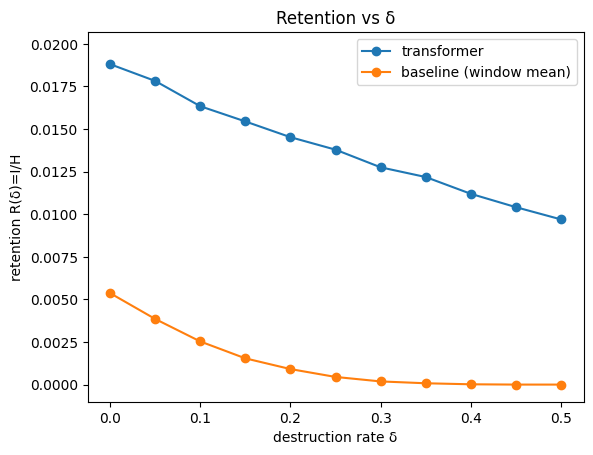

saved: step7_run_20260201_125554.json


In [11]:
d = [r["delta"] for r in results]
mi_tf = [r["MI_transformer"] for r in results]
mi_b  = [r["MI_baseline_window"] for r in results]
r_tf  = [r["R_transformer"] for r in results]
r_b   = [r["R_baseline_window"] for r in results]

plt.figure()
plt.plot(d, mi_tf, marker="o")
plt.plot(d, mi_b, marker="o")
plt.xlabel("destruction rate δ")
plt.ylabel("mutual information I(Z; Ŷ) [bits]")
plt.title("MI vs δ")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(d, r_tf, marker="o")
plt.plot(d, r_b, marker="o")
plt.xlabel("destruction rate δ")
plt.ylabel("retention R(δ)=I/H")
plt.title("Retention vs δ")
plt.legend(["transformer", "baseline (window mean)"])
plt.ylim(-0.001, max(r_tf)*1.1)
plt.show()

run = {
    "config": {
        "T": T,
        "K": K,
        "window": window,
        "mask_ratio": mask_ratio,
        "bins": bins.tolist(),
        "deltas": d,
        "destruction": "bitflip_X",
        "seed_world": seed_world,
        "seed_nodes": seed_nodes,
        "seed_destroy": 999,
        "model_weights": "run1_clean_model.pt",
        "model_hparams": {
            "d_model": 128, "nhead": 4, "num_layers": 3, "dim_ff": 256, "dropout": 0.1
        }
    },
    "results": results
}

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"step7_run_{stamp}.json"
with open(fname, "w") as f:
    json.dump(run, f, indent=2)
print("saved:", fname)
